# Urdu Sarcasm Detection 

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip -q install emoji arabic-reshaper python-bidi gensim
!pip -q install transformers accelerate sentencepiece

## Imports

In [3]:
import os, re, math, json, random, string, itertools, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

import emoji
import joblib
import arabic_reshaper
from bidi.algorithm import get_display

import torch
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from scipy.sparse import hstack, csr_matrix
from scipy.stats import chi2

warnings.filterwarnings('ignore')

In [4]:
SEED = 42

def set_seed(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", DEVICE)

device: cuda


In [5]:
os.chdir('/content')
DATA_PATH = "/content/drive/MyDrive/Copy of urdu_sarcastic_dataset.csv"
OUT_DIR = "/content/sarcasm_artifacts"
os.makedirs(OUT_DIR, exist_ok=True)

In [6]:
# urdu font for plots
FONT_PATH = '/content/drive/MyDrive/NotoNastaliqUrdu-VariableFont_wght.ttf'
font_manager.fontManager.addfont(FONT_PATH)
urdu_font = font_manager.FontProperties(fname=FONT_PATH, size=11)

def ur(text):
    return get_display(arabic_reshaper.reshape(str(text)))

sns.set_theme(style='whitegrid')
LABEL_NAME = {0: 'Non-sarcastic', 1: 'Sarcastic'}
PALETTE = {'Non-sarcastic': 'steelblue', 'Sarcastic': 'indianred'}

## Load Data

In [7]:
df = pd.read_csv(DATA_PATH)[['urdu_text', 'is_sarcastic']]
print(df.shape)
df.head()

(20060, 2)


,urdu_text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہ...,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی...,1.0
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپ...,0.0
3,نہیں پائین 😎,0.0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی...,1.0


In [8]:
print(df.isna().sum())
df = df.dropna(subset=['urdu_text', 'is_sarcastic'])
df['urdu_text'] = df['urdu_text'].astype(str).str.strip()
df = df[df['urdu_text'].str.len() > 0]
df['label'] = df['is_sarcastic'].astype(int)
print(df.shape)

urdu_text       105
is_sarcastic     56
dtype: int64
(19955, 3)


In [9]:
# exact duplicates
before = len(df)
df = df.drop_duplicates(subset=['urdu_text', 'label'])
print("duplicates removed:", before - len(df))

duplicates removed: 4095


In [10]:
# same text with both labels = label noise, drop it
n_labels = df.groupby('urdu_text')['label'].nunique()
conflict = n_labels[n_labels > 1].index
print("texts with conflicting labels:", len(conflict))

df = df[~df['urdu_text'].isin(conflict)].reset_index(drop=True)
print("final shape:", df.shape)

texts with conflicting labels: 646
final shape: (14568, 3)


In [11]:
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True).round(3))

label
0    8661
1    5907
Name: count, dtype: int64
label
0    0.595
1    0.405
Name: proportion, dtype: float64


## Surface Cues

In [12]:
URL_RE     = re.compile(r'(https?://\S+|www\.\S+)')
MENTION_RE = re.compile(r'@\w+')
HASHTAG_RE = re.compile(r'#(\w+)')
QUOTE_RE   = re.compile(r"``|''|[\"“”‘’«»]")
ELONG_RE   = re.compile(r'([^\W\d_])\1{2,}')
LATIN_RE   = re.compile(r'[A-Za-z]')
DOTS_RE    = re.compile(r'(\.{2,}|۔{2,}|…)')

In [13]:
# hashtags that literally say the label -> leakage
LEAK_TAGS = {'sarcasm', 'sarcastic', 'satire', 'irony', 'طنز', 'طنزومزاح', 'مزاح', 'طنزیہ'}
DROP_LEAK_TAGS = True

In [ ]:
def base_emoji(e):

    return re.sub('[️\U0001F3FB-\U0001F3FF]', '', e)

def get_emojis(t):
    return [base_emoji(e['emoji']) for e in emoji.emoji_list(t)]

df['emojis'] = df['urdu_text'].apply(get_emojis)
df['n_emoji'] = df['emojis'].str.len()
df['has_emoji'] = df['n_emoji'] > 0

In [15]:
LAUGH_EMO = {'😂', '🤣', '😆', '😅', '😁', '😹', '😄', '😀', '😃'}
MOCK_EMO  = {'😜', '😝', '😛', '😉', '😏', '🙄', '🤔', '🤪', '🤭', '😒', '🙃', '🤓', '😷', '🐕', '🤡', '😬'}

df['n_laugh'] = df['emojis'].apply(lambda l: sum(e in LAUGH_EMO for e in l))
df['n_mock'] = df['emojis'].apply(lambda l: sum(e in MOCK_EMO for e in l))

In [16]:
df['hashtags'] = df['urdu_text'].apply(lambda t: [h.lower() for h in HASHTAG_RE.findall(t)])
df['n_hashtag'] = df['hashtags'].str.len()
df['has_hashtag'] = df['n_hashtag'] > 0
# hashtag count without the label-word tags (used as a model feature)
df['n_hashtag_clean'] = df['hashtags'].apply(lambda l: sum(h not in LEAK_TAGS for h in l))

In [17]:
df['n_mention'] = df['urdu_text'].str.count(MENTION_RE.pattern)
df['has_url'] = df['urdu_text'].str.contains(URL_RE.pattern)
df['n_excl'] = df['urdu_text'].str.count('!')
df['n_ques'] = df['urdu_text'].str.count(r'[?؟]')
df['has_dots'] = df['urdu_text'].str.contains(DOTS_RE.pattern)
df['n_quotes'] = df['urdu_text'].apply(lambda t: len(QUOTE_RE.findall(t)))
df['n_elong'] = df['urdu_text'].apply(lambda t: len(ELONG_RE.findall(t)))

In [18]:
df['latin_ratio'] = df['urdu_text'].apply(lambda t: len(LATIN_RE.findall(t)) / max(len(t), 1))
df['has_latin'] = df['latin_ratio'] > 0
df['n_words'] = df['urdu_text'].str.split().str.len()
df['n_chars'] = df['urdu_text'].str.len()

In [19]:
cue_cols = ['has_emoji', 'n_emoji', 'n_laugh', 'n_mock', 'has_hashtag', 'n_mention', 'has_url',
            'n_excl', 'n_ques', 'has_dots', 'n_quotes', 'n_elong', 'has_latin', 'latin_ratio',
            'n_words', 'n_chars']
cue_table = df.groupby('label')[cue_cols].mean().T.rename(columns=LABEL_NAME)
cue_table['sarc / non ratio'] = cue_table['Sarcastic'] / cue_table['Non-sarcastic'].replace(0, np.nan)
cue_table.round(3)

label,Non-sarcastic,Sarcastic,sarc / non ratio
has_emoji,0.881,0.668,0.758
n_emoji,2.204,1.644,0.746
n_laugh,0.699,0.863,1.236
n_mock,0.189,0.275,1.455
has_hashtag,0.003,0.119,39.475
n_mention,0.014,0.167,11.789
has_url,0.003,0.058,18.518
n_excl,0.001,0.026,20.527
n_ques,0.058,0.099,1.725
has_dots,0.163,0.155,0.951


## Emoji Analysis

In [20]:
n_cls = df['label'].value_counts()

emo_summary = pd.DataFrame({
    '% posts with emoji': df.groupby('label')['has_emoji'].mean() * 100,
    'mean emojis / post': df.groupby('label')['n_emoji'].mean(),
    'total emojis': df.groupby('label')['n_emoji'].sum(),
    'unique emojis': df.groupby('label')['emojis'].apply(lambda s: len(set(e for l in s for e in l))),
}).rename(index=LABEL_NAME)
display(emo_summary.round(2))

print("P(sarcastic | emoji)    =", round(df[df.has_emoji]['label'].mean(), 3))
print("P(sarcastic | no emoji) =", round(df[~df.has_emoji]['label'].mean(), 3))

,% posts with emoji,mean emojis / post,total emojis,unique emojis
label,,,,
Non-sarcastic,88.12,2.20,19088,474
Sarcastic,66.82,1.64,9709,322


P(sarcastic | emoji)    = 0.341
P(sarcastic | no emoji) = 0.656


In [21]:
def class_doc_freq(data, col):
    # number of posts per class containing each item
    c = {0: Counter(), 1: Counter()}
    for items, l in zip(data[col], data['label']):
        c[l].update(set(items))
    return c

def log_odds_table(c, min_total=20, alpha=1.0):
    # > 0 means more typical of sarcastic posts
    n1, n0 = n_cls[1], n_cls[0]
    rows = []
    for k in set(c[0]) | set(c[1]):
        a, b = c[1][k], c[0][k]
        if a + b < min_total:
            continue
        p1 = (a + alpha) / (n1 + 2 * alpha)
        p0 = (b + alpha) / (n0 + 2 * alpha)
        rows.append(dict(item=k, sarcastic_posts=a, non_sarcastic_posts=b, total=a + b,
                         pct_of_sarc_posts=100 * a / n1, pct_of_non_posts=100 * b / n0,
                         sarc_share=a / (a + b),
                         log_odds=np.log(p1 / (1 - p1)) - np.log(p0 / (1 - p0))))
    return pd.DataFrame(rows).sort_values('log_odds', ascending=False).reset_index(drop=True)

In [22]:
emo_df = log_odds_table(class_doc_freq(df, 'emojis'), min_total=20)
emo_df['name'] = emo_df['item'].apply(lambda e: emoji.demojize(e).strip(':').replace('_', ' '))

top_sarc = emo_df.sort_values('pct_of_sarc_posts', ascending=False).head(15)
top_non = emo_df.sort_values('pct_of_non_posts', ascending=False).head(15)

In [23]:
print("Most frequent emojis in sarcastic posts")
display(top_sarc[['item', 'name', 'pct_of_sarc_posts', 'pct_of_non_posts']].round(2))
print("Most frequent emojis in non-sarcastic posts")
display(top_non[['item', 'name', 'pct_of_non_posts', 'pct_of_sarc_posts']].round(2))

Most frequent emojis in sarcastic posts


,item,name,pct_of_sarc_posts,pct_of_non_posts
24,😂,face with tears of joy,26.85,23.14
9,😜,winking face with tongue,6.52,3.75
4,😁,beaming face with smiling eyes,5.50,2.83
20,🤣,rolling on the floor laughing,4.01,2.94
3,😅,grinning face with sweat,2.69,1.28
2,😉,winking face,2.23,1.03
13,😀,grinning face,2.17,1.28
53,🙏,folded hands,1.95,3.08
22,😝,squinting face with tongue,1.91,1.44
14,😆,grinning squinting face,1.83,1.12


Most frequent emojis in non-sarcastic posts


,item,name,pct_of_non_posts,pct_of_sarc_posts
24,😂,face with tears of joy,23.14,26.85
92,❤,red heart,7.57,1.19
106,💔,broken heart,4.55,0.36
9,😜,winking face with tongue,3.75,6.52
85,😍,smiling face with heart-eyes,3.29,0.58
53,🙏,folded hands,3.08,1.95
20,🤣,rolling on the floor laughing,2.94,4.01
4,😁,beaming face with smiling eyes,2.83,5.50
84,🔥,fire,2.74,0.52
102,🌹,rose,2.70,0.27


In [24]:
print("Most sarcastic emojis (log-odds)")
display(emo_df.head(12)[['item', 'name', 'sarcastic_posts', 'non_sarcastic_posts', 'log_odds']].round(3))
print("Most non-sarcastic emojis (log-odds)")
display(emo_df.tail(12).iloc[::-1][['item', 'name', 'sarcastic_posts', 'non_sarcastic_posts', 'log_odds']].round(3))

Most sarcastic emojis (log-odds)


,item,name,sarcastic_posts,non_sarcastic_posts,log_odds
0,🐕,dog,22,11,1.036
1,🤓,nerd face,18,11,0.844
2,😉,winking face,132,89,0.785
3,😅,grinning face with sweat,159,111,0.754
4,😁,beaming face with smiling eyes,325,245,0.692
5,😄,grinning face with smiling eyes,85,65,0.654
6,🤪,zany face,31,24,0.632
7,🖐,hand with fingers splayed,13,10,0.625
8,😷,face with medical mask,38,30,0.615
9,😜,winking face with tongue,385,325,0.581


Most non-sarcastic emojis (log-odds)


,item,name,sarcastic_posts,non_sarcastic_posts,log_odds
111,🔄,counterclockwise arrows button,0,48,-3.515
110,✅,check mark button,0,31,-3.087
109,💓,beating heart,0,30,-3.055
108,❣,heart exclamation,2,80,-2.922
107,💞,revolving hearts,4,110,-2.730
106,💔,broken heart,21,394,-2.548
105,♥,heart suit,8,146,-2.426
104,🌺,hibiscus,3,58,-2.315
103,💐,bouquet,3,58,-2.315
102,🌹,rose,16,234,-2.268


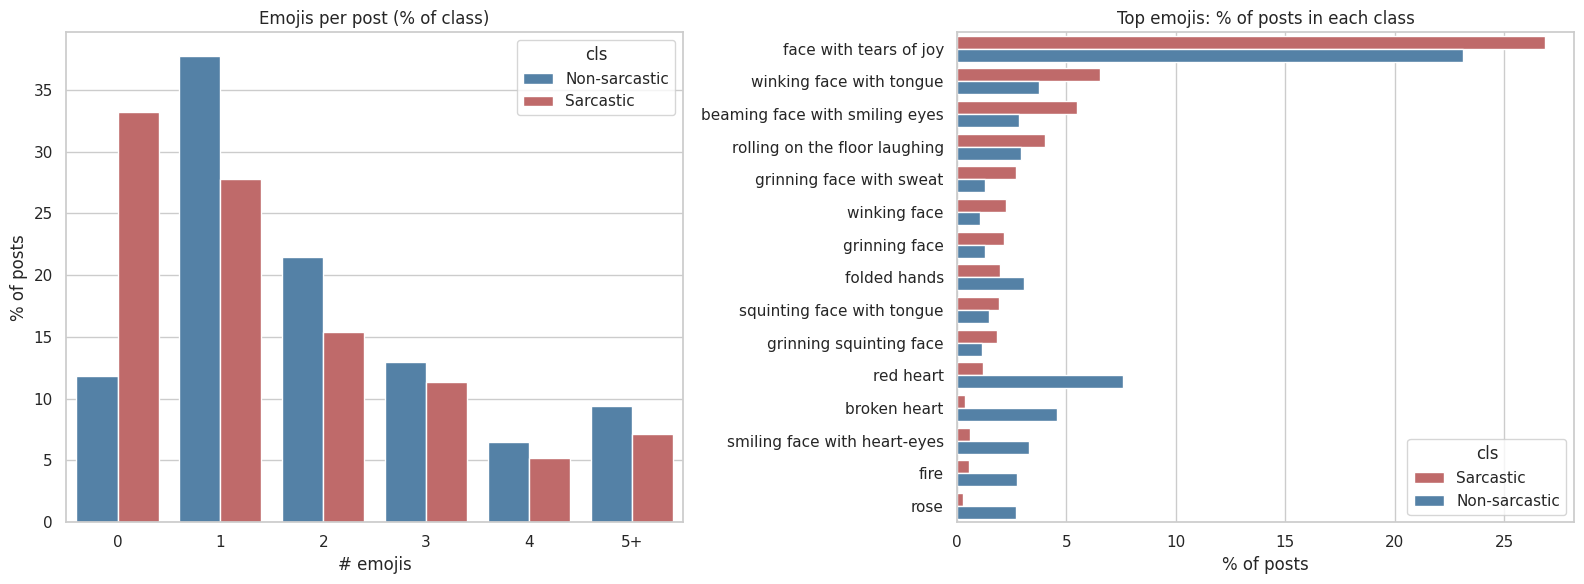

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cnt = df.assign(bucket=df['n_emoji'].clip(upper=5).astype(str).replace('5', '5+'),
                cls=df['label'].map(LABEL_NAME))
share = cnt.groupby('cls')['bucket'].value_counts(normalize=True).mul(100).rename('pct').reset_index()
sns.barplot(data=share, x='bucket', y='pct', hue='cls', palette=PALETTE, ax=axes[0],
            order=['0', '1', '2', '3', '4', '5+'])
axes[0].set(title='Emojis per post (% of class)', xlabel='# emojis', ylabel='% of posts')

union = list(dict.fromkeys(list(top_sarc['item'][:10]) + list(top_non['item'][:10])))
u = emo_df.set_index('item').loc[union].reset_index()
long = u.melt(id_vars=['name'], value_vars=['pct_of_sarc_posts', 'pct_of_non_posts'],
              var_name='cls', value_name='pct')
long['cls'] = long['cls'].map({'pct_of_sarc_posts': 'Sarcastic', 'pct_of_non_posts': 'Non-sarcastic'})
sns.barplot(data=long, y='name', x='pct', hue='cls', palette=PALETTE, ax=axes[1])
axes[1].set(title='Top emojis: % of posts in each class', xlabel='% of posts', ylabel='')

plt.tight_layout()
plt.show()

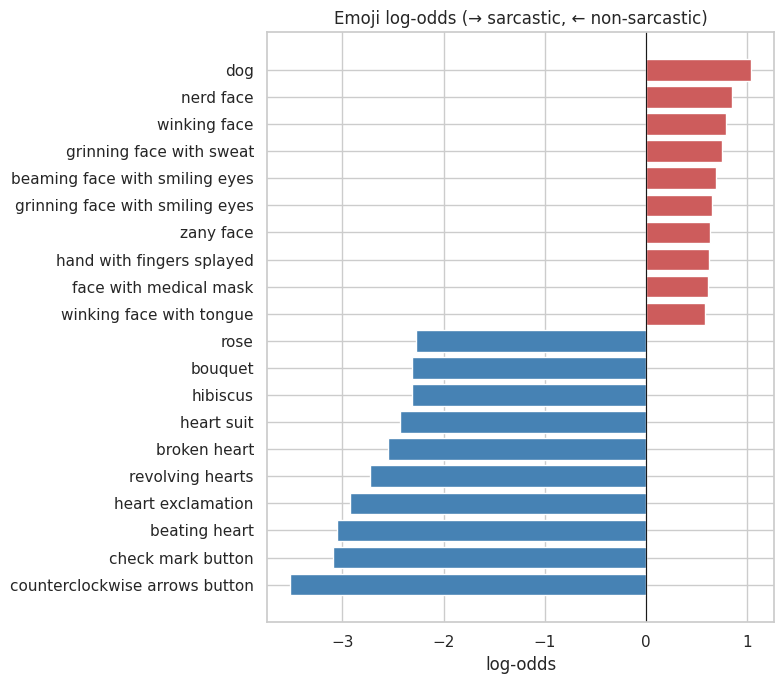

In [26]:
lo = pd.concat([emo_df.head(10), emo_df.tail(10)])

plt.figure(figsize=(8, 7))
plt.barh(lo['name'], lo['log_odds'], color=['indianred' if v > 0 else 'steelblue' for v in lo['log_odds']])
plt.gca().invert_yaxis()
plt.axvline(0, color='k', lw=.8)
plt.title('Emoji log-odds (→ sarcastic, ← non-sarcastic)')
plt.xlabel('log-odds')
plt.tight_layout()
plt.show()

## Hashtag Analysis

In [27]:
hash_summary = pd.DataFrame({
    '% posts with hashtag': df.groupby('label')['has_hashtag'].mean() * 100,
    'unique hashtags': df.groupby('label')['hashtags'].apply(lambda s: len(set(h for l in s for h in l))),
}).rename(index=LABEL_NAME)
display(hash_summary.round(2))

print("P(sarcastic | hashtag)    =", round(df[df.has_hashtag]['label'].mean(), 3))
print("P(sarcastic | no hashtag) =", round(df[~df.has_hashtag]['label'].mean(), 3))

,% posts with hashtag,unique hashtags
label,,
Non-sarcastic,0.30,33
Sarcastic,11.85,525


P(sarcastic | hashtag)    = 0.964
P(sarcastic | no hashtag) = 0.376


In [28]:
hash_df = log_odds_table(class_doc_freq(df, 'hashtags'), min_total=5)
cols = ['item', 'sarcastic_posts', 'non_sarcastic_posts', 'sarc_share', 'log_odds']

print("Most frequent hashtags — sarcastic")
display(hash_df.sort_values('sarcastic_posts', ascending=False).head(15)[cols].round(3))
print("Most sarcasm-indicative hashtags")
display(hash_df.head(10)[cols].round(3))

Most frequent hashtags — sarcastic


,item,sarcastic_posts,non_sarcastic_posts,sarc_share,log_odds
1,sarcasm,376,5,0.987,4.588
0,طنز,150,0,1.000,5.426
2,sarcastic,56,0,1.000,4.435
3,آئےناں_کنٹینرتے,31,0,1.000,3.854
4,مزاح,21,0,1.000,3.477
9,satire,16,1,0.941,2.525
12,pakistan,12,1,0.923,2.256
5,صفی,11,0,1.000,2.869
6,طنزومزاح,9,0,1.000,2.687
18,pti,9,1,0.900,1.993


Most sarcasm-indicative hashtags


,item,sarcastic_posts,non_sarcastic_posts,sarc_share,log_odds
0,طنز,150,0,1.000,5.426
1,sarcasm,376,5,0.987,4.588
2,sarcastic,56,0,1.000,4.435
3,آئےناں_کنٹینرتے,31,0,1.000,3.854
4,مزاح,21,0,1.000,3.477
5,صفی,11,0,1.000,2.869
6,طنزومزاح,9,0,1.000,2.687
7,imrankhan,8,0,1.000,2.581
8,اردو,8,0,1.000,2.581
9,satire,16,1,0.941,2.525


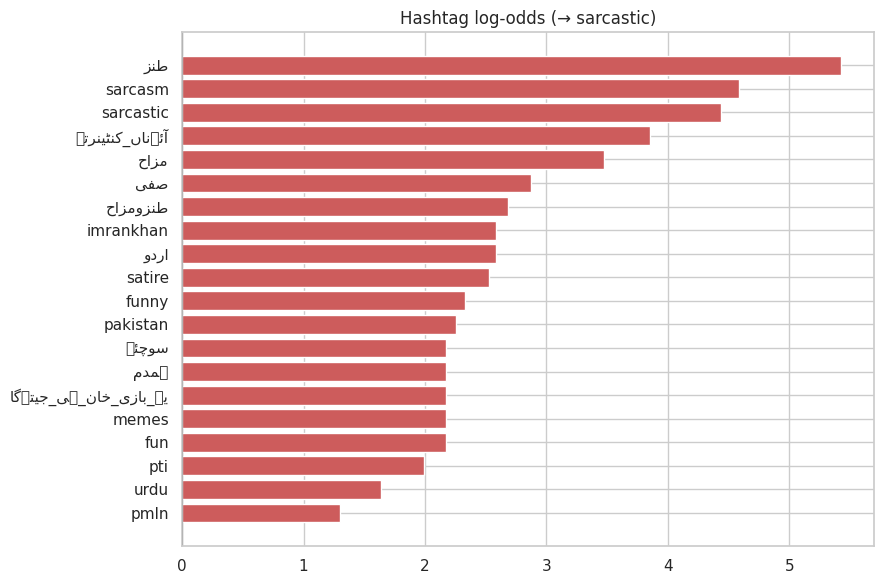

In [29]:
hd = pd.concat([hash_df.head(10), hash_df.tail(10)]).drop_duplicates('item')

plt.figure(figsize=(9, 6))
plt.barh(range(len(hd)), hd['log_odds'], color=['indianred' if v > 0 else 'steelblue' for v in hd['log_odds']])
plt.yticks(range(len(hd)), [ur(h) for h in hd['item']])
plt.gca().invert_yaxis()
plt.axvline(0, color='k', lw=.8)
plt.title('Hashtag log-odds (→ sarcastic)')
plt.tight_layout()
plt.show()

## Text Normalization

In [30]:
import kagglehub
sw_path = kagglehub.dataset_download("itsnobita/urdu-stopwords")
print(sw_path)

Using Colab cache for faster access to the 'urdu-stopwords' dataset.
/kaggle/input/urdu-stopwords


In [31]:
CHAR_MAP = str.maketrans({'ي': 'ی', 'ى': 'ی', 'ك': 'ک', 'ه': 'ہ', 'ة': 'ہ', 'ۃ': 'ہ',
                          'أ': 'ا', 'إ': 'ا', 'ٱ': 'ا'})
DIACRITICS = re.compile(r'[ً-ٰٟۖ-ۭـ]')
DIGITS_RE = re.compile(r'[0-9٠-٩۰-۹]+')
URDU_PUNCT = '،؛؟۔٪٫٬“”‘’«»…–—'
PUNCT_TABLE = str.maketrans({c: ' ' for c in string.punctuation + URDU_PUNCT})

In [32]:
# keep negations / question words / intensifiers even when removing stopwords
KEEP_CUES = {'بہت', 'بالکل', 'واقعی', 'کبھی', 'کیوں', 'کیسے', 'کیا', 'واہ', 'بس', 'ہی', 'نہیں', 'نہ', 'مت'}

sw = pd.read_csv(os.path.join(sw_path, "urdu_stopwords.csv"))['stopword']
STOP = {DIACRITICS.sub('', str(w).translate(CHAR_MAP)).strip() for w in sw if isinstance(w, str)}
STOP = {w for w in STOP if w} - KEEP_CUES
print("stopwords:", len(STOP))

stopwords: 131


In [33]:
def normalize(text, keep_emoji=True, keep_hashtag=True, keep_punct=True, remove_stop=False, mark_special=True):
    t = str(text).lower()
    t = URL_RE.sub(' xxurl ', t)
    t = MENTION_RE.sub(' xxuser ', t)

    def tag_repl(m):
        tag = m.group(1)
        if DROP_LEAK_TAGS and tag in LEAK_TAGS:
            return ' '
        return ' xxhash ' + tag.replace('_', ' ') + ' ' if keep_hashtag else ' '
    t = HASHTAG_RE.sub(tag_repl, t)

    t = t.translate(CHAR_MAP)
    t = DIACRITICS.sub('', t)
    t = DIGITS_RE.sub(' xxnum ', t)
    t = ELONG_RE.sub(r'\1\1 xxelong ', t)

    if keep_punct:
        t = QUOTE_RE.sub(' xxquote ', t)
        t = re.sub(r'!{2,}', ' xxexclrep ', t).replace('!', ' xxexcl ')
        t = re.sub(r'[?؟]{2,}', ' xxquesrep ', t)
        t = re.sub(r'[?؟]', ' xxques ', t)
        t = DOTS_RE.sub(' xxdots ', t)

    t = emoji.replace_emoji(t, replace=(lambda e, d: f' {base_emoji(e)} ') if keep_emoji else ' ')
    t = t.translate(PUNCT_TABLE)
    toks = t.split()
    if remove_stop:
        toks = [w for w in toks if w not in STOP]
    if not mark_special:
        toks = [w for w in toks if not w.startswith('xx')]
    return ' '.join(toks)

In [ ]:
# light cleaning for the char-CNN and the transformer (they should see emojis/punctuation themselves)
def minimal(text):
    t = URL_RE.sub(' http ', str(text))
    t = MENTION_RE.sub(' @user ', t)
    if DROP_LEAK_TAGS:
        t = HASHTAG_RE.sub(lambda m: ' ' if m.group(1).lower() in LEAK_TAGS else m.group(0), t)
    t = t.translate(CHAR_MAP)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['txt_minimal'] = df['urdu_text'].apply(minimal)

In [35]:
VARIANTS = {
    'norm_full':     dict(keep_emoji=True,  keep_hashtag=True,  keep_punct=True,  remove_stop=False),
    'norm_no_emoji': dict(keep_emoji=False, keep_hashtag=True,  keep_punct=True,  remove_stop=False),
    'norm_no_punct': dict(keep_emoji=True,  keep_hashtag=True,  keep_punct=False, remove_stop=False),
    'norm_no_hash':  dict(keep_emoji=True,  keep_hashtag=False, keep_punct=True,  remove_stop=False),
    'norm_no_stop':  dict(keep_emoji=True,  keep_hashtag=True,  keep_punct=True,  remove_stop=True),
    'aggressive':    dict(keep_emoji=False, keep_hashtag=False, keep_punct=False, remove_stop=True, mark_special=False),
}

for name, kw in VARIANTS.items():
    df[f'txt_{name}'] = df['urdu_text'].apply(lambda t: normalize(t, **kw))

In [36]:
for i in df.sample(3, random_state=1).index:
    print('RAW       :', df['urdu_text'][i][:160])
    print('norm_full :', df['txt_norm_full'][i][:160])
    print('minimal   :', df['txt_minimal'][i][:160])
    print('aggressive:', df['txt_aggressive'][i][:160], '\n')

RAW       : آج ابو کے اک دوست ان سے ملنے آئے میں چائے دینے گئی تو کسی چینل پہ اس کا کوئی ٹکر چل رہا تھا ابو کہہ رہے انکل کو اب یہ خواجہ آصف پہ بھونکے گا جس نے ہمیشہ ان سے م
norm_full : آج ابو کے اک دوست ان سے ملنے آئے میں چائے دینے گئی تو کسی چینل پہ اس کا کوئی ٹکر چل رہا تھا ابو کہہ رہے انکل کو اب یہ خواجہ آصف پہ بھونکے گا جس نے ہمیشہ ان سے م
minimal   : آج ابو کے اک دوست ان سے ملنے آئے میں چائے دینے گئی تو کسی چینل پہ اس کا کوئی ٹکر چل رہا تھا ابو کہہ رہے انکل کو اب یہ خواجہ آصف پہ بھونکے گا جس نے ہمیشہ ان سے م
aggressive: آج ابو اک دوست سے ملنے آئے چائے دینے گئی کسی چینل پہ ٹکر چل رہا تھا ابو کہہ رہے انکل اب خواجہ آصف پہ بھونکے گا جس نے ہمیشہ سے منہ اوپر لتر کھایا الیکشن بےغیرت ک 

RAW       : دنیا کے تین سب سے  امن پسند اشخاص:
 
#sarcasm 
#justfaking
#JoinRSS http://t.co/g1kAJ5qdMo
norm_full : دنیا کے تین سب سے امن پسند اشخاص xxhash justfaking xxhash joinrss xxurl
minimal   : دنیا کے تین سب سے امن پسند اشخاص: #justfaking #JoinRSS http
aggressive: دنیا تین سے امن پسند اشخاص 

RAW   

## Word Distribution

In [37]:
df['content_tokens'] = df['urdu_text'].apply(
    lambda t: normalize(t, keep_emoji=False, keep_hashtag=True, keep_punct=False,
                        remove_stop=True, mark_special=False).split())

In [38]:
def vocab_stats(tok_lists):
    c = Counter(w for l in tok_lists for w in l)
    n_tok = sum(c.values())
    stats = dict(posts=len(tok_lists), tokens=n_tok, vocabulary=len(c),
                 type_token_ratio=len(c) / max(n_tok, 1),
                 hapax_pct=100 * sum(v == 1 for v in c.values()) / max(len(c), 1),
                 mean_content_words=n_tok / max(len(tok_lists), 1))
    return stats, c

stats, counters = {}, {}
for lab, name in [(None, 'All'), (0, 'Non-sarcastic'), (1, 'Sarcastic')]:
    s = df['content_tokens'] if lab is None else df.loc[df['label'] == lab, 'content_tokens']
    stats[name], counters[name] = vocab_stats(list(s))
display(pd.DataFrame(stats).T.round(3))

,posts,tokens,vocabulary,type_token_ratio,hapax_pct,mean_content_words
All,14568.0,203740.0,20542.0,0.101,49.800,13.985
Non-sarcastic,8661.0,100369.0,14444.0,0.144,54.140,11.589
Sarcastic,5907.0,103371.0,12585.0,0.122,46.579,17.500


In [39]:
v0, v1 = set(counters['Non-sarcastic']), set(counters['Sarcastic'])
print(f"vocab overlap (Jaccard): {len(v0 & v1) / len(v0 | v1):.3f}")
df.groupby(df['label'].map(LABEL_NAME))['n_words'].describe().round(2)

vocab overlap (Jaccard): 0.316


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Non-sarcastic,8661.0,15.67,12.50,1.0,7.0,12.0,20.0,70.0
Sarcastic,5907.0,23.93,13.06,1.0,15.0,21.0,29.0,71.0


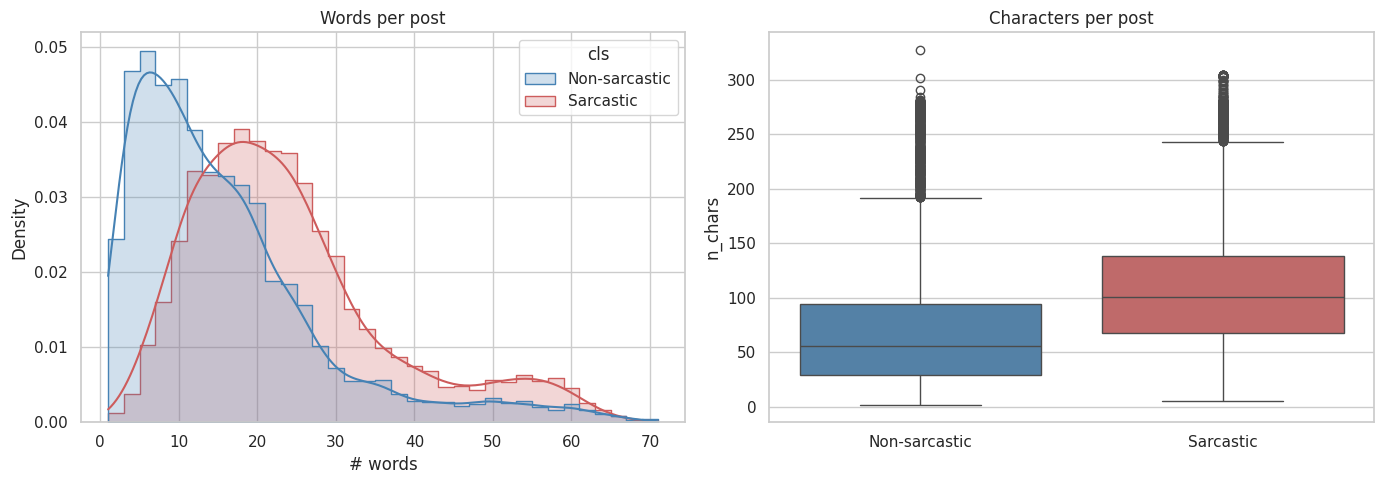

In [40]:
plot_df = df.assign(cls=df['label'].map(LABEL_NAME))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=plot_df, x='n_words', hue='cls', palette=PALETTE, bins=35, stat='density',
             common_norm=False, element='step', kde=True, ax=axes[0])
axes[0].set(title='Words per post', xlabel='# words')

sns.boxplot(data=plot_df, x='cls', y='n_chars', palette=PALETTE, ax=axes[1])
axes[1].set(title='Characters per post', xlabel='')

plt.tight_layout()
plt.show()

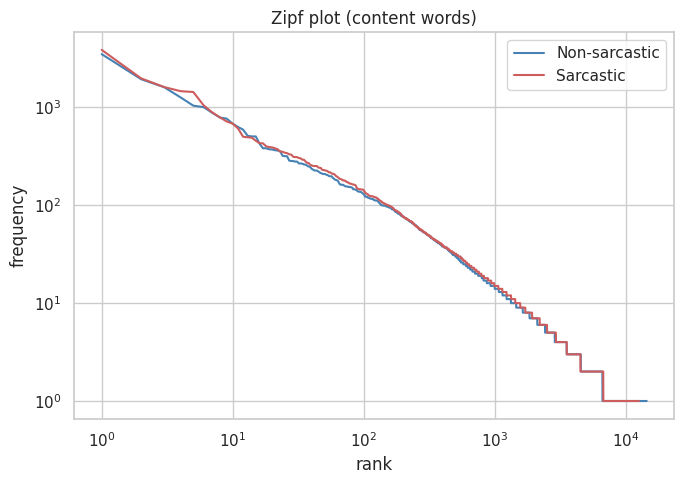

In [41]:
plt.figure(figsize=(7, 5))
for name, col in [('Non-sarcastic', 'steelblue'), ('Sarcastic', 'indianred')]:
    f = np.array(sorted(counters[name].values(), reverse=True))
    plt.loglog(np.arange(1, len(f) + 1), f, color=col, label=name)
plt.title('Zipf plot (content words)')
plt.xlabel('rank')
plt.ylabel('frequency')
plt.legend()
plt.tight_layout()
plt.show()

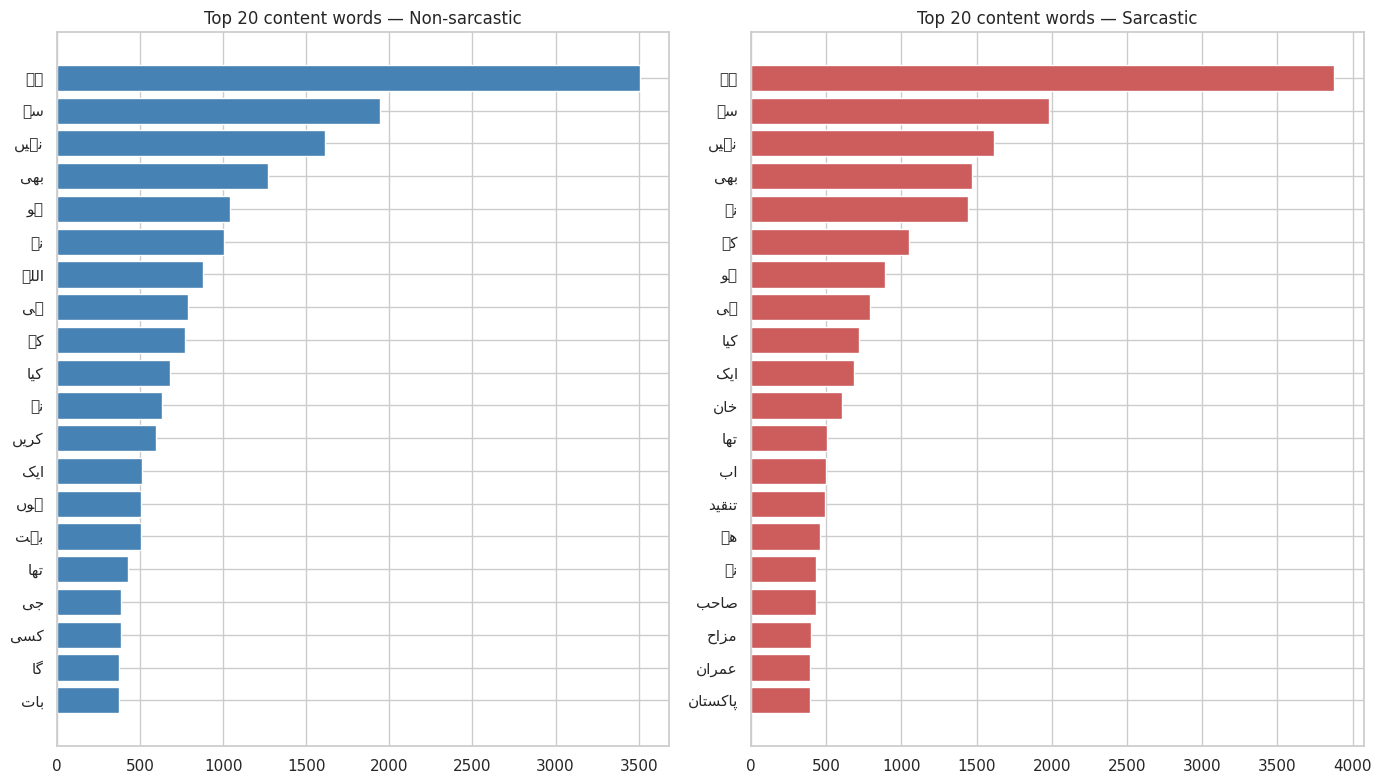

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, name, col in [(axes[0], 'Non-sarcastic', 'steelblue'), (axes[1], 'Sarcastic', 'indianred')]:
    top = counters[name].most_common(20)
    ax.barh(range(20), [c for _, c in top], color=col)
    ax.set_yticks(range(20))
    ax.set_yticklabels([ur(w) for w, _ in top])
    ax.invert_yaxis()
    ax.set_title(f'Top 20 content words — {name}')
plt.tight_layout()
plt.show()

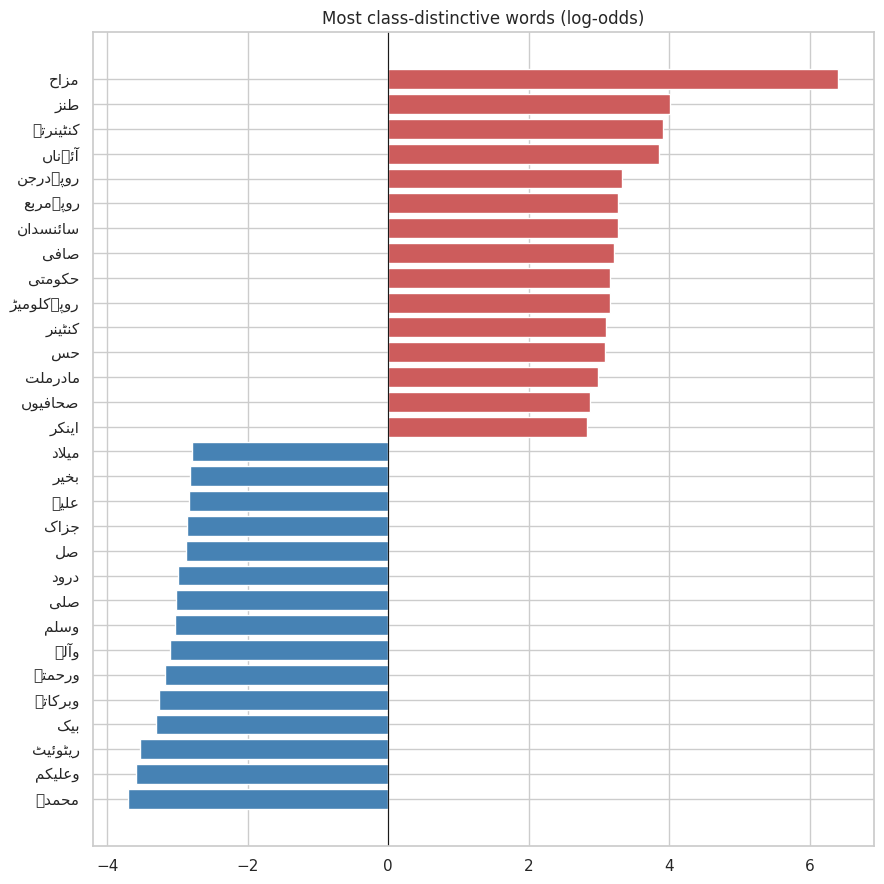

In [43]:
word_lo = log_odds_table(class_doc_freq(df, 'content_tokens'), min_total=15)
wd = pd.concat([word_lo.head(15), word_lo.tail(15)])

plt.figure(figsize=(9, 9))
plt.barh(range(len(wd)), wd['log_odds'], color=['indianred' if v > 0 else 'steelblue' for v in wd['log_odds']])
plt.yticks(range(len(wd)), [ur(w) for w in wd['item']])
plt.gca().invert_yaxis()
plt.axvline(0, color='k', lw=.8)
plt.title('Most class-distinctive words (log-odds)')
plt.tight_layout()
plt.show()

In [44]:
for lab in [0, 1]:
    print(f"\n--- {LABEL_NAME[lab]} ---")
    for t in df[df['label'] == lab]['urdu_text'].sample(5, random_state=7):
        print(' •', t[:180])


--- Non-sarcastic ---
 • وہ تیر مجھے کیونکر نہ لگا جس تیر سے گھائل تھا اصغر ع 💔
 • ووٹ چور ، رقبہ چور ، پیزا  بیچنے والے کرپٹ اور عوام دشمن جرنیلوں کو سزا ضرور ملےگی انشا الله
 • صحیییح
 • صرف مانع تھی حیا بند قبا کھلنے تلک پھر تو وہ جان حیا ایسا کھلا ایسا کھلا  اردوزبان
 • علی ع جسے سجدہ کر رہا ہے ۔ وہی خدا ہے وہی خدا ہے // 💚🌹

--- Sarcastic ---
 • انسان کو بس ایک آدھ بار ہی آزمانا چاہیئے پھر جو اس کا رنگ ہوتا ہے، وہی اصلی رنگ ہوتا ہے۔اُس کے بعد وہ آپ کو نہیں، آپ خود کو دھوکہ دیتے ہیں.🔥 😔😏😔
 • وزیر دفاع بیچارہ خود بیساکھیوں کے سہارے ہے 😂
 • سندھ پولیس اگر کام نہیں کر سکتی تو انڈیا چلی جائے 😷
 • انڈیا بھی مریخ پحنچ گیا ۔ لیکن ہم استعفی لیے بغیر نہیں جایئں گے ! 

#GoNawazGo #Sarcasm
 • عمران خان میرا منہ کالا کرنا چاہتے تھے۔ خواجہ آصف نہ تو وزیراعظم اتنے فارغ ہیں اور نہ ہی خواجہ آصف کی اتنی حیثیت۔ عثمان ڈار 😂


## Train / Val / Test Split

In [45]:
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp['label'], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

y_train, y_val, y_test = train_df['label'].values, val_df['label'].values, test_df['label'].values
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{n:5s} {len(d):6d}  sarcastic={d['label'].mean():.3f}")

train  10197  sarcastic=0.406
val     2185  sarcastic=0.405
test    2186  sarcastic=0.405


In [46]:
RESULTS, PREDS, PROBS, VAL_PROBS = [], {}, {}, {}

def evaluate(name, y_true, y_pred, show=True):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    row = dict(model=name, acc=accuracy_score(y_true, y_pred), P0=p[0], R0=r[0], F1_0=f[0],
               P1=p[1], R1=r[1], F1_1=f[1], macro_F1=f1_score(y_true, y_pred, average='macro'))
    if show:
        print(f"\n=== {name} ===")
        print(classification_report(y_true, y_pred, target_names=['non-sarc', 'sarc'], digits=4))
    return row

def best_threshold(y, p):
    # tuned on validation only
    grid = np.linspace(0.2, 0.8, 61)
    scores = [f1_score(y, (p >= t).astype(int), average='macro') for t in grid]
    return float(grid[int(np.argmax(scores))])

## TF-IDF Ablation

In [47]:
def make_vec(kind):
    w = lambda: TfidfVectorizer(token_pattern=r'\S+', ngram_range=(1, 3), min_df=2, max_df=0.9,
                                sublinear_tf=True, lowercase=False, max_features=150_000)
    c = lambda: TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, max_df=0.9,
                                sublinear_tf=True, lowercase=False, max_features=300_000)
    return {'word': w(), 'char': c(), 'word+char': make_union(w(), c())}[kind]

def make_clf(name, C):
    if name == 'lr':
        return LogisticRegression(C=C, max_iter=3000, class_weight='balanced', solver='liblinear')
    if name == 'svm':
        return LinearSVC(C=C, class_weight='balanced')
    return ComplementNB(alpha=C)

def fit_select(Xtr, Xva, clf_name):
    grid = (0.03, 0.1, 0.3, 1.0) if clf_name == 'nb' else (0.1, 0.3, 1, 3, 10)
    best = None
    for C in grid:
        m = make_clf(clf_name, C).fit(Xtr, y_train)
        s = f1_score(y_val, m.predict(Xva), average='macro')
        if best is None or s > best[0]:
            best = (s, C, m)
    return best

In [48]:
abl = []
for var in VARIANTS:
    col = f'txt_{var}'
    for kind in ['word', 'char', 'word+char']:
        vec = make_vec(kind)
        Xtr = vec.fit_transform(train_df[col])
        Xva = vec.transform(val_df[col])
        s, C, _ = fit_select(Xtr, Xva, 'lr')
        abl.append(dict(variant=var, features=kind, C=C, val_macro_F1=round(s, 4)))
        print(f"{var:14s} {kind:10s} C={C:<5} val Macro-F1={s:.4f}")
abl = pd.DataFrame(abl)

norm_full      word       C=3     val Macro-F1=0.7880
norm_full      char       C=1     val Macro-F1=0.7968
norm_full      word+char  C=1     val Macro-F1=0.7950
norm_no_emoji  word       C=3     val Macro-F1=0.7757
norm_no_emoji  char       C=1     val Macro-F1=0.7922
norm_no_emoji  word+char  C=1     val Macro-F1=0.7924
norm_no_punct  word       C=3     val Macro-F1=0.7833
norm_no_punct  char       C=1     val Macro-F1=0.7931
norm_no_punct  word+char  C=3     val Macro-F1=0.7930
norm_no_hash   word       C=3     val Macro-F1=0.7856
norm_no_hash   char       C=1     val Macro-F1=0.7937
norm_no_hash   word+char  C=0.3   val Macro-F1=0.7893
norm_no_stop   word       C=3     val Macro-F1=0.7821
norm_no_stop   char       C=1     val Macro-F1=0.7929
norm_no_stop   word+char  C=0.3   val Macro-F1=0.7962
aggressive     word       C=10    val Macro-F1=0.7568
aggressive     char       C=0.3   val Macro-F1=0.7777
aggressive     word+char  C=1     val Macro-F1=0.7781


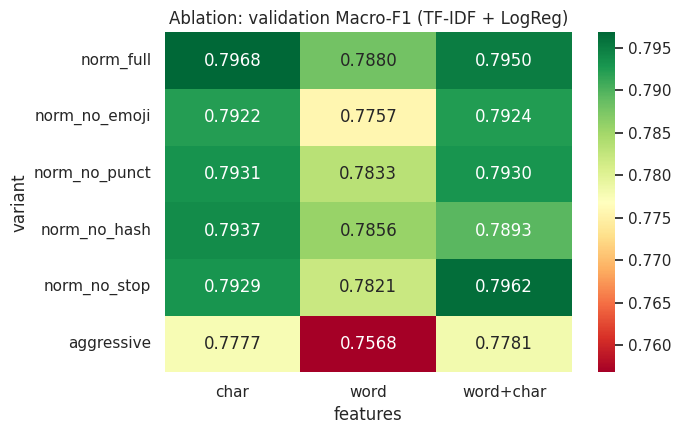

In [49]:
pivot = abl.pivot(index='variant', columns='features', values='val_macro_F1').loc[list(VARIANTS)]

plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='RdYlGn')
plt.title('Ablation: validation Macro-F1 (TF-IDF + LogReg)')
plt.tight_layout()
plt.show()

## BPE Features

In [50]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

def train_bpe(texts, vocab_size):
    bpe = Tokenizer(models.BPE(unk_token='[UNK]'))
    bpe.pre_tokenizer = pre_tokenizers.Whitespace()
    bpe.train_from_iterator(list(texts), trainers.BpeTrainer(
        vocab_size=vocab_size, min_frequency=3, special_tokens=['[UNK]']))
    return bpe

def bpe_encode(bpe, texts):
    return [' '.join(e.tokens) for e in bpe.encode_batch(list(texts))]

def bpe_vec():
    return TfidfVectorizer(token_pattern=r'\S+', ngram_range=(1, 4), min_df=2,
                           sublinear_tf=True, lowercase=False, max_features=200_000)

def char_vec():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, max_df=0.9,
                           sublinear_tf=True, lowercase=False, max_features=300_000)

In [51]:
# 16k and 32k gave identical scores before (vocab saturates), so only 4k/8k/16k
bpe_rows = []
for var in VARIANTS:
    col = f'txt_{var}'
    for vs in (4000, 8000, 16000):
        bpe = train_bpe(train_df[col], vs)
        tr_b, va_b = bpe_encode(bpe, train_df[col]), bpe_encode(bpe, val_df[col])

        vb = bpe_vec()
        s, C, _ = fit_select(vb.fit_transform(tr_b), vb.transform(va_b), 'lr')
        bpe_rows.append(dict(variant=var, features=f'bpe{vs//1000}k', C=C, val_macro_F1=round(s, 4)))

        vb, vc = bpe_vec(), char_vec()
        Xtr = hstack([vb.fit_transform(tr_b), vc.fit_transform(train_df[col])]).tocsr()
        Xva = hstack([vb.transform(va_b), vc.transform(val_df[col])]).tocsr()
        s, C, _ = fit_select(Xtr, Xva, 'lr')
        bpe_rows.append(dict(variant=var, features=f'bpe{vs//1000}k+char', C=C, val_macro_F1=round(s, 4)))
        print(f"{var:14s} bpe{vs//1000}k done")

norm_full      bpe4k done
norm_full      bpe8k done
norm_full      bpe16k done
norm_no_emoji  bpe4k done
norm_no_emoji  bpe8k done
norm_no_emoji  bpe16k done
norm_no_punct  bpe4k done
norm_no_punct  bpe8k done
norm_no_punct  bpe16k done
norm_no_hash   bpe4k done
norm_no_hash   bpe8k done
norm_no_hash   bpe16k done
norm_no_stop   bpe4k done
norm_no_stop   bpe8k done
norm_no_stop   bpe16k done
aggressive     bpe4k done
aggressive     bpe8k done
aggressive     bpe16k done


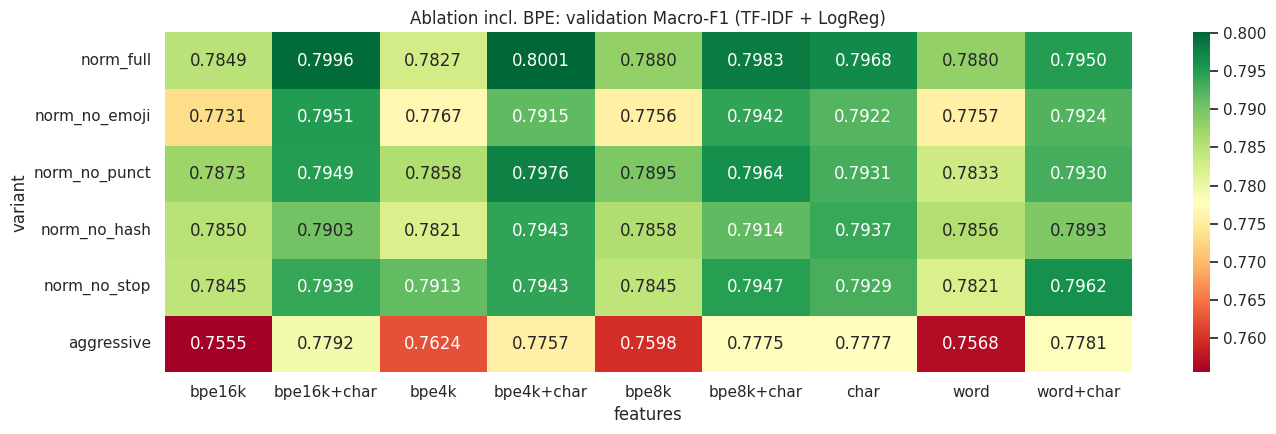

In [52]:
abl_all = pd.concat([abl, pd.DataFrame(bpe_rows)], ignore_index=True)
pivot_all = abl_all.pivot(index='variant', columns='features', values='val_macro_F1').loc[list(VARIANTS)]

plt.figure(figsize=(14, 4.5))
sns.heatmap(pivot_all, annot=True, fmt='.4f', cmap='RdYlGn')
plt.title('Ablation incl. BPE: validation Macro-F1 (TF-IDF + LogReg)')
plt.tight_layout()
plt.show()

In [53]:
base = pivot[['word', 'char', 'word+char']].max(axis=1)
bpe_cols = [c for c in pivot_all.columns if c.startswith('bpe')]
pivot_all[bpe_cols].sub(base, axis=0).round(4)

features,bpe16k,bpe16k+char,bpe4k,bpe4k+char,bpe8k,bpe8k+char
variant,,,,,,
norm_full,-0.0119,0.0028,-0.0141,0.0033,-0.0088,0.0015
norm_no_emoji,-0.0193,0.0027,-0.0157,-0.0009,-0.0168,0.0018
norm_no_punct,-0.0058,0.0018,-0.0073,0.0045,-0.0036,0.0033
norm_no_hash,-0.0087,-0.0034,-0.0116,0.0006,-0.0079,-0.0023
norm_no_stop,-0.0117,-0.0023,-0.0049,-0.0019,-0.0117,-0.0015
aggressive,-0.0226,0.0011,-0.0157,-0.0024,-0.0183,-0.0006


## Classical Models

In [54]:
def build_features(col, kind):
    # returns Xtr, Xva, Xte; everything is fit on train only
    if not kind.startswith('bpe'):
        vec = make_vec(kind)
        return vec.fit_transform(train_df[col]), vec.transform(val_df[col]), vec.transform(test_df[col])

    vs = int(kind[3:].split('k')[0]) * 1000
    bpe = train_bpe(train_df[col], vs)
    tr_b, va_b, te_b = (bpe_encode(bpe, d[col]) for d in (train_df, val_df, test_df))

    vb = bpe_vec()
    parts = [[vb.fit_transform(tr_b)], [vb.transform(va_b)], [vb.transform(te_b)]]
    if kind.endswith('+char'):
        vc = char_vec()
        parts[0].append(vc.fit_transform(train_df[col]))
        parts[1].append(vc.transform(val_df[col]))
        parts[2].append(vc.transform(test_df[col]))
    return tuple(hstack(p).tocsr() for p in parts)

In [55]:
best_row = abl_all.loc[abl_all['val_macro_F1'].idxmax()]
BEST_VAR, BEST_KIND = best_row['variant'], best_row['features']
BEST_COL = f'txt_{BEST_VAR}'
print("best config:", BEST_VAR, BEST_KIND, "val Macro-F1 =", best_row['val_macro_F1'])

Xtr, Xva, Xte = build_features(BEST_COL, BEST_KIND)
print(Xtr.shape)

best config: norm_full bpe4k+char val Macro-F1 = 0.8001
(10197, 118978)


In [56]:
for clf_name, label in [('lr', 'TFIDF+LogReg'), ('svm', 'TFIDF+LinearSVM'), ('nb', 'TFIDF+ComplementNB')]:
    s, C, m = fit_select(Xtr, Xva, clf_name)
    if clf_name == 'svm':
        PROBS[label] = m.decision_function(Xte)
        PREDS[label] = m.predict(Xte)
    else:
        VAL_PROBS[label] = m.predict_proba(Xva)[:, 1]
        thr = best_threshold(y_val, VAL_PROBS[label])
        PROBS[label] = m.predict_proba(Xte)[:, 1]
        PREDS[label] = (PROBS[label] >= thr).astype(int)
    if clf_name == 'lr':
        tfidf_lr = m
    RESULTS.append(evaluate(f"{label} [{BEST_VAR}, {BEST_KIND}]", y_test, PREDS[label]))
    RESULTS[-1]['key'] = label


=== TFIDF+LogReg [norm_full, bpe4k+char] ===
              precision    recall  f1-score   support

    non-sarc     0.8607    0.8462    0.8534      1300
        sarc     0.7797    0.7991    0.7893       886

    accuracy                         0.8271      2186
   macro avg     0.8202    0.8226    0.8213      2186
weighted avg     0.8279    0.8271    0.8274      2186


=== TFIDF+LinearSVM [norm_full, bpe4k+char] ===
              precision    recall  f1-score   support

    non-sarc     0.8639    0.8400    0.8518      1300
        sarc     0.7744    0.8059    0.7898       886

    accuracy                         0.8262      2186
   macro avg     0.8192    0.8229    0.8208      2186
weighted avg     0.8276    0.8262    0.8267      2186


=== TFIDF+ComplementNB [norm_full, bpe4k+char] ===
              precision    recall  f1-score   support

    non-sarc     0.8245    0.8785    0.8507      1300
        sarc     0.8027    0.7257    0.7623       886

    accuracy                       

## Phrases + Handcrafted Features

In [57]:
def learn_phrases(texts, min_count=5, pmi_thr=3.0):
    uni, bi = Counter(), Counter()
    for t in texts:
        toks = [w for w in t.split() if not w.startswith('xx')]
        uni.update(toks)
        bi.update(zip(toks, toks[1:]))
    N = sum(uni.values())
    phrases = {}
    for (a, b), c in bi.items():
        if c < min_count:
            continue
        pmi = math.log(c * N / (uni[a] * uni[b]))
        if pmi >= pmi_thr:
            phrases[(a, b)] = pmi
    return phrases

def apply_phrases(text, phrases):
    toks, out, i = text.split(), [], 0
    while i < len(toks):
        if i + 1 < len(toks) and (toks[i], toks[i + 1]) in phrases:
            out.append(toks[i] + '_' + toks[i + 1])
            i += 2
        else:
            out.append(toks[i])
            i += 1
    return ' '.join(out)

In [58]:
PHRASES = learn_phrases(train_df['txt_norm_full'])
print(len(PHRASES), "phrases")
print([ur(a + ' ' + b) for (a, b), _ in sorted(PHRASES.items(), key=lambda x: -x[1])[:10]])

for d in (train_df, val_df, test_df):
    d['txt_phrases'] = d['txt_norm_full'].apply(lambda t: apply_phrases(t, PHRASES))

1989 phrases
['ﺮﭩﭘﺎﮐ ﯽﻠﯿﮨ', 'ﻦﯾﺪﻟﺍ ﺀﻼﻋ', 'pak army', 'ﮏﯿﻠﻋ ﻡﻼﺴﻟﺍﻭ', 'ﻕﺮﻏ ﺍﮍﯿﺑ', 'ﭺﻮﻠﮔ ﻢﻟﺎﮔ', 'ﺩﻮﻌﺴﻣ ﺭﺎﻤﻋ', 'ﮏﯿﭨﺍ ﭦﺭﺎﮨ', 'ﺕﺎﺟ ﮧﻗﻼﻋ', 'ﺮﮐﺎﺷ ﺮﺑﺎﺻ']


In [59]:
POS_WORDS = {'واہ', 'زبردست', 'شاندار', 'کمال', 'بہترین', 'اچھا', 'اچھی', 'خوب', 'مبارک',
             'شکریہ', 'عظیم', 'لاجواب', 'ماشاءاللہ', 'سبحان', 'جیو', 'قربان'}
NEG = {'نہیں', 'نہ', 'مت', 'نا', 'بغیر'}

In [60]:
def handcrafted(d):
    toks = d['txt_norm_full'].str.split()
    f = pd.DataFrame({
        'log_words': np.log1p(d['n_words']),
        'log_chars': np.log1p(d['n_chars']),
        'n_emoji': d['n_emoji'],
        'emoji_per_word': d['n_emoji'] / d['n_words'].clip(lower=1),
        'n_laugh': d['n_laugh'],
        'n_mock': d['n_mock'],
        'n_excl': d['n_excl'],
        'n_ques': d['n_ques'],
        'has_dots': d['has_dots'].astype(int),
        'n_quotes': d['n_quotes'],
        'n_elong': d['n_elong'],
        'latin_ratio': d['latin_ratio'],
        'n_hashtag': d['n_hashtag_clean'],
        'n_mention': d['n_mention'],
        'has_url': d['has_url'].astype(int),
        'n_neg': toks.apply(lambda l: sum(w in NEG for w in l)),
        'n_pos_word': toks.apply(lambda l: sum(w in POS_WORDS for w in l)),
    })
    # positive word + laughing/mocking emoji = classic sarcasm pattern
    f['incongruity'] = ((f['n_pos_word'] > 0) & ((f['n_laugh'] + f['n_mock']) > 0)).astype(int)
    return f.astype(float)

In [61]:
HC_tr, HC_va, HC_te = handcrafted(train_df), handcrafted(val_df), handcrafted(test_df)
hc_scaler = StandardScaler().fit(HC_tr)
H_tr = hc_scaler.transform(HC_tr)
H_va = hc_scaler.transform(HC_va)
H_te = hc_scaler.transform(HC_te)
HC_tr.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_words,10197.0,2.77,0.71,0.69,2.30,2.83,3.26,4.28
log_chars,10197.0,4.22,0.79,1.10,3.74,4.33,4.77,5.72
n_emoji,10197.0,1.99,2.57,0.00,1.00,1.00,3.00,71.00
emoji_per_word,10197.0,0.20,0.55,0.00,0.03,0.10,0.22,34.00
n_laugh,10197.0,0.77,1.68,0.00,0.00,0.00,1.00,60.00
n_mock,10197.0,0.22,0.77,0.00,0.00,0.00,0.00,16.00
n_excl,10197.0,0.01,0.17,0.00,0.00,0.00,0.00,6.00
n_ques,10197.0,0.08,0.48,0.00,0.00,0.00,0.00,19.00
has_dots,10197.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
n_quotes,10197.0,0.09,0.52,0.00,0.00,0.00,0.00,15.00


In [62]:
T_tr, T_va, T_te = build_features('txt_phrases', BEST_KIND)
F_tr = hstack([T_tr, csr_matrix(H_tr)]).tocsr()
F_va = hstack([T_va, csr_matrix(H_va)]).tocsr()
F_te = hstack([T_te, csr_matrix(H_te)]).tocsr()

In [63]:
s, C, fe_lr = fit_select(F_tr, F_va, 'lr')
print(f"val Macro-F1 phrases+handcrafted: {s:.4f}  vs plain TF-IDF: {best_row['val_macro_F1']:.4f}")

VAL_PROBS['FE-LR'] = fe_lr.predict_proba(F_va)[:, 1]
thr = best_threshold(y_val, VAL_PROBS['FE-LR'])
PROBS['FE-LR'] = fe_lr.predict_proba(F_te)[:, 1]
PREDS['FE-LR'] = (PROBS['FE-LR'] >= thr).astype(int)
RESULTS.append(evaluate('TFIDF+Phrases+Handcrafted (LogReg)', y_test, PREDS['FE-LR']))
RESULTS[-1]['key'] = 'FE-LR'

val Macro-F1 phrases+handcrafted: 0.8074  vs plain TF-IDF: 0.8001

=== TFIDF+Phrases+Handcrafted (LogReg) ===
              precision    recall  f1-score   support

    non-sarc     0.8690    0.8423    0.8555      1300
        sarc     0.7786    0.8138    0.7958       886

    accuracy                         0.8307      2186
   macro avg     0.8238    0.8280    0.8256      2186
weighted avg     0.8324    0.8307    0.8313      2186



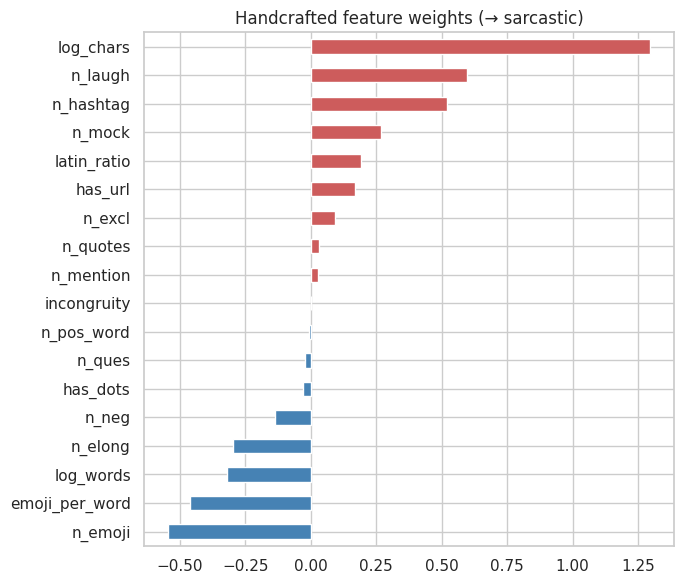

In [64]:
coef = pd.Series(fe_lr.coef_[0][-H_tr.shape[1]:], index=HC_tr.columns).sort_values()

plt.figure(figsize=(7, 6))
coef.plot.barh(color=['steelblue' if v < 0 else 'indianred' for v in coef])
plt.title('Handcrafted feature weights (→ sarcastic)')
plt.tight_layout()
plt.show()

## BiLSTM + CharCNN

In [65]:
NN_COL, CHAR_COL = 'txt_norm_full', 'txt_minimal'
MAXLEN, MAXCHAR = 80, 300
EMB_DIM = 200

In [66]:
def build_vocab(texts, min_freq=2, max_size=40000):
    c = Counter(w for t in texts for w in t.split())
    itos = ['<pad>', '<unk>'] + [w for w, f in c.most_common(max_size) if f >= min_freq]
    return {w: i for i, w in enumerate(itos)}

def build_char_vocab(texts, min_freq=3):
    c = Counter(ch for t in texts for ch in t)
    itos = ['<pad>', '<unk>'] + [ch for ch, f in c.most_common() if f >= min_freq]
    return {ch: i for i, ch in enumerate(itos)}

In [67]:
def encode_words(texts, vocab, maxlen):
    ids = np.zeros((len(texts), maxlen), dtype=np.int64)
    lens = np.zeros(len(texts), dtype=np.int64)
    for i, t in enumerate(texts):
        seq = ([vocab.get(w, 1) for w in t.split()] or [1])[-maxlen:]   # keep the end of the post
        ids[i, :len(seq)] = seq
        lens[i] = len(seq)
    return torch.tensor(ids), torch.tensor(lens)

def encode_chars(texts, cvocab, maxc):
    ids = np.zeros((len(texts), maxc), dtype=np.int64)
    for i, t in enumerate(texts):
        seq = ([cvocab.get(ch, 1) for ch in t] or [1])[-maxc:]
        ids[i, :len(seq)] = seq
    return torch.tensor(ids)

In [68]:
wvocab = build_vocab(train_df[NN_COL])
cvocab = build_char_vocab(train_df[CHAR_COL])
print("word vocab:", len(wvocab), "| char vocab:", len(cvocab))

word vocab: 8764 | char vocab: 617


In [69]:
def make_loader(d, H, shuffle, bs=64):
    w, l = encode_words(d[NN_COL].tolist(), wvocab, MAXLEN)
    c = encode_chars(d[CHAR_COL].tolist(), cvocab, MAXCHAR)
    ds = TensorDataset(w, l, c, torch.tensor(H, dtype=torch.float32), torch.tensor(d['label'].values))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

tr_loader = make_loader(train_df, H_tr, True)
va_loader = make_loader(val_df, H_va, False)
te_loader = make_loader(test_df, H_te, False)

In [70]:
# word2vec trained on the train split only (vocab must exist before this cell)
from gensim.models import Word2Vec, FastText

EMB_TYPE = 'fasttext_cbow'          # 'cbow' | 'skipgram' | 'fasttext_cbow'
sentences = [t.split() for t in train_df[NN_COL]]
common = dict(vector_size=EMB_DIM, window=5, min_count=2, workers=4, epochs=30,
              negative=10, sample=1e-4, seed=SEED)

if EMB_TYPE == 'cbow':
    w2v = Word2Vec(sentences, sg=0, **common)
elif EMB_TYPE == 'skipgram':
    w2v = Word2Vec(sentences, sg=1, **common)
else:
    w2v = FastText(sentences, sg=0, min_n=2, max_n=5, **common)

In [71]:
pretrained = torch.randn(len(wvocab), EMB_DIM) * 0.1
pretrained[0] = 0
hit = 0
for w, i in wvocab.items():
    if i < 2:
        continue
    if w in w2v.wv:
        pretrained[i] = torch.tensor(w2v.wv[w])
        hit += 1
print(f"{EMB_TYPE} coverage: {hit}/{len(wvocab)}")

fasttext_cbow coverage: 8762/8764


In [72]:
class HybridSarcasmNet(nn.Module):
    def __init__(self, vocab_size, n_chars, n_meta, emb_dim=200, hid=128, char_dim=48, n_filters=96, pretrained=None):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if pretrained is not None:
            self.emb.weight.data.copy_(pretrained)
        self.emb_drop = nn.Dropout(0.3)
        self.lstm = nn.LSTM(emb_dim, hid, num_layers=2, bidirectional=True, batch_first=True, dropout=0.3)
        self.att = nn.Sequential(nn.Linear(2 * hid, hid), nn.Tanh(), nn.Linear(hid, 1))
        self.cemb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(char_dim, n_filters, k, padding=k // 2) for k in (3, 4, 5)])
        self.meta = nn.Sequential(nn.Linear(n_meta, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(4 * hid + 3 * n_filters + 32, 128),
                                  nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))

    def forward(self, w, lengths, c, m):
        mask = w != 0
        x = self.emb_drop(self.emb(w))
        packed = pack_padded_sequence(x, lengths.cpu().clamp(min=1), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=w.size(1))

        scores = self.att(out).squeeze(-1).masked_fill(~mask, -1e9)
        alpha = torch.softmax(scores, dim=-1)
        att_vec = (alpha.unsqueeze(-1) * out).sum(1)
        max_vec = out.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values

        ce = self.cemb(c).transpose(1, 2)
        cvec = torch.cat([torch.relu(conv(ce)).max(-1).values for conv in self.convs], dim=-1)
        return self.head(torch.cat([att_vec, max_vec, cvec, self.meta(m)], dim=-1))

In [73]:
# class weights, used by the BiLSTM and the transformer
CLASS_W = torch.tensor(len(y_train) / (2 * np.bincount(y_train)), dtype=torch.float, device=DEVICE)
print(CLASS_W)

@torch.no_grad()
def nn_predict(model, loader):
    model.eval()
    out = []
    for w, l, c, m, _ in loader:
        logits = model(w.to(DEVICE), l, c.to(DEVICE), m.to(DEVICE))
        out.append(torch.softmax(logits, -1)[:, 1].cpu())
    return torch.cat(out).numpy()

tensor([0.8411, 1.2330], device='cuda:0')


In [74]:
def train_nn(model, epochs=15, lr=2e-3, patience=3):
    crit = nn.CrossEntropyLoss(weight=CLASS_W, label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tr_loader))
    best_f1, best_state, bad, hist = -1, None, 0, []

    for ep in range(1, epochs + 1):
        model.train()
        tot = 0
        for w, l, c, m, y in tr_loader:
            opt.zero_grad()
            loss = crit(model(w.to(DEVICE), l, c.to(DEVICE), m.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            tot += loss.item() * len(y)

        p = nn_predict(model, va_loader)
        f1 = f1_score(y_val, (p >= .5).astype(int), average='macro')
        hist.append(dict(epoch=ep, train_loss=tot / len(train_df), val_macro_F1=f1))
        print(f"epoch {ep:2d}  train_loss={tot / len(train_df):.4f}  val Macro-F1={f1:.4f}")

        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print("early stop")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

In [75]:
set_seed()
nn_model = HybridSarcasmNet(len(wvocab), len(cvocab), H_tr.shape[1], emb_dim=EMB_DIM, pretrained=pretrained).to(DEVICE)
nn_model, nn_hist = train_nn(nn_model)

epoch  1  train_loss=0.6112  val Macro-F1=0.7582
epoch  2  train_loss=0.4949  val Macro-F1=0.7309
epoch  3  train_loss=0.4665  val Macro-F1=0.7757
epoch  4  train_loss=0.4324  val Macro-F1=0.7967
epoch  5  train_loss=0.3926  val Macro-F1=0.7963
epoch  6  train_loss=0.3333  val Macro-F1=0.8029
epoch  7  train_loss=0.2948  val Macro-F1=0.7844
epoch  8  train_loss=0.2604  val Macro-F1=0.7833
epoch  9  train_loss=0.2341  val Macro-F1=0.7907
early stop


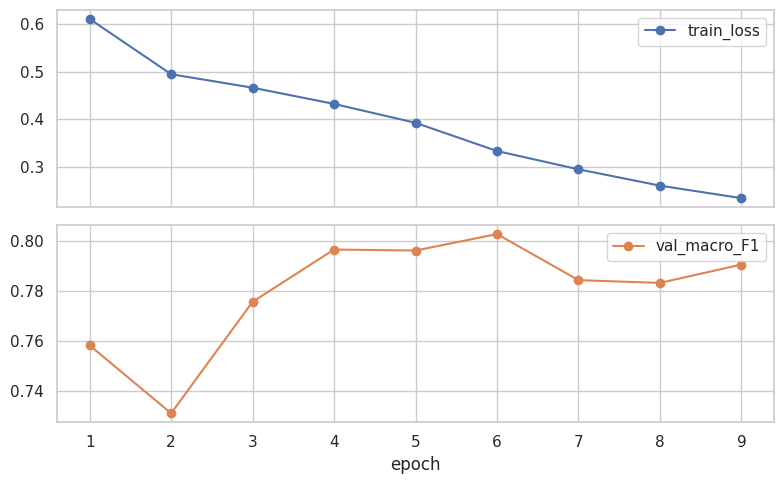

In [76]:
nn_hist.set_index('epoch').plot(subplots=True, figsize=(8, 5), marker='o')
plt.tight_layout()
plt.show()

In [77]:
VAL_PROBS['NN'] = nn_predict(nn_model, va_loader)
thr = best_threshold(y_val, VAL_PROBS['NN'])
PROBS['NN'] = nn_predict(nn_model, te_loader)
PREDS['NN'] = (PROBS['NN'] >= thr).astype(int)
RESULTS.append(evaluate('BiLSTM-Attn + CharCNN + features', y_test, PREDS['NN']))
RESULTS[-1]['key'] = 'NN'


=== BiLSTM-Attn + CharCNN + features ===
              precision    recall  f1-score   support

    non-sarc     0.8857    0.8169    0.8499      1300
        sarc     0.7589    0.8454    0.7998       886

    accuracy                         0.8285      2186
   macro avg     0.8223    0.8311    0.8249      2186
weighted avg     0.8343    0.8285    0.8296      2186



## XLM-RoBERTa Fine-tuning

In [78]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup

RUN_TRANSFORMER = torch.cuda.is_available()
if not RUN_TRANSFORMER:
    print("No GPU! Runtime -> Change runtime type -> T4 GPU, then re-run. Skipping transformer.")
else:
    gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(torch.cuda.get_device_name(0), f"{gpu_gb:.1f} GB")

Tesla T4 15.6 GB


In [79]:
TF_MODEL = "xlm-roberta-large"     # if it is too slow / OOM: "xlm-roberta-base" or "cardiffnlp/twitter-xlm-roberta-base"
TF_COL = 'txt_minimal'
MAX_LEN, BATCH, ACCUM, EPOCHS = 128, 8, 4, 4      # effective batch 32
LR = 1e-5 if 'large' in TF_MODEL else 2e-5
CKPT = '/content/best_transformer.pt'

In [80]:
hf_tok = AutoTokenizer.from_pretrained(TF_MODEL)
lens = [len(x) for x in hf_tok(train_df[TF_COL].tolist()[:2000])['input_ids']]
print("subword length p95 / max:", np.percentile(lens, 95), max(lens))

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

subword length p95 / max: 72.0 151


In [81]:
class TxtDS(TorchDataset):
    def __init__(self, texts, labels):
        self.enc = hf_tok(list(texts), truncation=True, max_length=MAX_LEN)
        self.y = list(map(int, labels))
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}
        d['labels'] = self.y[i]
        return d

collate = DataCollatorWithPadding(hf_tok)
tf_tr = DataLoader(TxtDS(train_df[TF_COL], y_train), batch_size=BATCH, shuffle=True, collate_fn=collate)
tf_va = DataLoader(TxtDS(val_df[TF_COL], y_val), batch_size=64, collate_fn=collate)
tf_te = DataLoader(TxtDS(test_df[TF_COL], y_test), batch_size=64, collate_fn=collate)

In [82]:
use_amp = torch.cuda.is_available()
amp_dtype = torch.bfloat16 if use_amp and torch.cuda.get_device_capability()[0] >= 8 else torch.float16

@torch.no_grad()
def tf_predict(model, loader):
    model.eval()
    out = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        b.pop('labels')
        with torch.autocast('cuda', dtype=amp_dtype, enabled=use_amp):
            logits = model(**b).logits
        out.append(torch.softmax(logits.float(), -1)[:, 1].cpu())
    return torch.cat(out).numpy()

In [83]:
def train_transformer(model_name, epochs=EPOCHS, lr=LR, patience=2):
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(DEVICE)

    no_decay = ('bias', 'LayerNorm.weight')
    groups = [{'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], 'weight_decay': 0.01},
              {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr)
    total = epochs * math.ceil(len(tf_tr) / ACCUM)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp and amp_dtype == torch.float16)
    crit = nn.CrossEntropyLoss(weight=CLASS_W)

    best_f1, bad, hist = -1, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad()
        tot = 0
        for step, b in enumerate(tf_tr):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            y = b.pop('labels')
            with torch.autocast('cuda', dtype=amp_dtype, enabled=use_amp):
                logits = model(**b).logits
            loss = crit(logits.float(), y) / ACCUM
            scaler.scale(loss).backward()
            tot += loss.item() * ACCUM
            if (step + 1) % ACCUM == 0 or step + 1 == len(tf_tr):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad()
                sched.step()

        p = tf_predict(model, tf_va)
        f1 = f1_score(y_val, (p >= .5).astype(int), average='macro')
        hist.append(dict(epoch=ep, train_loss=tot / len(tf_tr), val_macro_F1=f1))
        print(f"epoch {ep}  train_loss={tot / len(tf_tr):.4f}  val Macro-F1={f1:.4f}")
        if f1 < 0.45:
            print("  ! model predicts one class only -> try LR=8e-6 or xlm-roberta-base")

        if f1 > best_f1:
            best_f1, bad = f1, 0
            torch.save(model.state_dict(), CKPT)
        else:
            bad += 1
            if bad >= patience:
                print("early stop")
                break

    model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
    return model, pd.DataFrame(hist)

In [84]:
if RUN_TRANSFORMER:
    torch.cuda.empty_cache()
    tf_model, tf_hist = train_transformer(TF_MODEL)
    display(tf_hist)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1  train_loss=0.6800  val Macro-F1=0.5679
epoch 2  train_loss=0.4999  val Macro-F1=0.7693
epoch 3  train_loss=0.3973  val Macro-F1=0.7954
epoch 4  train_loss=0.3596  val Macro-F1=0.7950


,epoch,train_loss,val_macro_F1
0,1,0.679951,0.567934
1,2,0.499875,0.769318
2,3,0.397331,0.795360
3,4,0.359580,0.794963


In [85]:
if RUN_TRANSFORMER:
    VAL_PROBS['XLMR'] = tf_predict(tf_model, tf_va)
    thr = best_threshold(y_val, VAL_PROBS['XLMR'])
    PROBS['XLMR'] = tf_predict(tf_model, tf_te)
    PREDS['XLMR'] = (PROBS['XLMR'] >= thr).astype(int)
    RESULTS.append(evaluate(f'{TF_MODEL} (fine-tuned)', y_test, PREDS['XLMR']))
    RESULTS[-1]['key'] = 'XLMR'


=== xlm-roberta-large (fine-tuned) ===
              precision    recall  f1-score   support

    non-sarc     0.8689    0.8415    0.8550      1300
        sarc     0.7778    0.8138    0.7954       886

    accuracy                         0.8303      2186
   macro avg     0.8234    0.8277    0.8252      2186
weighted avg     0.8320    0.8303    0.8308      2186



## Ensemble

In [86]:
ens_keys = [k for k in ['TFIDF+LogReg', 'FE-LR', 'NN', 'XLMR'] if k in VAL_PROBS]
print("models in ensemble:", ens_keys)

P_va = np.vstack([VAL_PROBS[k] for k in ens_keys])
P_te = np.vstack([PROBS[k] for k in ens_keys])
grid = np.linspace(0.2, 0.8, 61)

def macro_f1_grid(y, p):
    # macro-F1 for every threshold in grid at once
    pred = p[None, :] >= grid[:, None]
    tp1 = (pred & (y == 1)).sum(1); fp1 = (pred & (y == 0)).sum(1); fn1 = (~pred & (y == 1)).sum(1)
    tp0 = (~pred & (y == 0)).sum(1); fp0 = fn1; fn0 = fp1
    f1_1 = 2 * tp1 / np.maximum(2 * tp1 + fp1 + fn1, 1)
    f1_0 = 2 * tp0 / np.maximum(2 * tp0 + fp0 + fn0, 1)
    return (f1_1 + f1_0) / 2

models in ensemble: ['TFIDF+LogReg', 'FE-LR', 'NN', 'XLMR']


In [87]:
# search weights on validation only
best = (-1, None, None)
steps = np.arange(0, 1.01, 0.1)
for w in itertools.product(steps, repeat=len(ens_keys)):
    w = np.array(w)
    if w.sum() == 0:
        continue
    w = w / w.sum()
    scores = macro_f1_grid(y_val, w @ P_va)
    i = scores.argmax()
    if scores[i] > best[0]:
        best = (scores[i], w, grid[i])

ens_f1, ens_w, ens_thr = best
print("weights:", {k: round(float(v), 2) for k, v in zip(ens_keys, ens_w)})
print("threshold:", round(float(ens_thr), 2), "| val Macro-F1:", round(float(ens_f1), 4))

weights: {'TFIDF+LogReg': 0.0, 'FE-LR': 0.62, 'NN': 0.31, 'XLMR': 0.06}
threshold: 0.51 | val Macro-F1: 0.8201


In [88]:
PROBS['ENS'] = ens_w @ P_te
PREDS['ENS'] = (PROBS['ENS'] >= ens_thr).astype(int)
RESULTS.append(evaluate('Weighted ensemble', y_test, PREDS['ENS']))
RESULTS[-1]['key'] = 'ENS'


=== Weighted ensemble ===
              precision    recall  f1-score   support

    non-sarc     0.8746    0.8423    0.8582      1300
        sarc     0.7805    0.8228    0.8011       886

    accuracy                         0.8344      2186
   macro avg     0.8276    0.8326    0.8296      2186
weighted avg     0.8365    0.8344    0.8350      2186



## Results

In [89]:
res_df = pd.DataFrame(RESULTS).sort_values('macro_F1', ascending=False).reset_index(drop=True)
res_df.drop(columns='key').to_csv(f'{OUT_DIR}/results.csv', index=False)
res_df.drop(columns='key').round(4)

,model,acc,P0,R0,F1_0,P1,R1,F1_1,macro_F1
0,Weighted ensemble,0.8344,0.8746,0.8423,0.8582,0.7805,0.8228,0.8011,0.8296
1,TFIDF+Phrases+Handcrafted (LogReg),0.8307,0.8690,0.8423,0.8555,0.7786,0.8138,0.7958,0.8256
2,xlm-roberta-large (fine-tuned),0.8303,0.8689,0.8415,0.8550,0.7778,0.8138,0.7954,0.8252
3,BiLSTM-Attn + CharCNN + features,0.8285,0.8857,0.8169,0.8499,0.7589,0.8454,0.7998,0.8249
4,"TFIDF+LogReg [norm_full, bpe4k+char]",0.8271,0.8607,0.8462,0.8534,0.7797,0.7991,0.7893,0.8213
5,"TFIDF+LinearSVM [norm_full, bpe4k+char]",0.8262,0.8639,0.8400,0.8518,0.7744,0.8059,0.7898,0.8208
6,"TFIDF+ComplementNB [norm_full, bpe4k+char]",0.8166,0.8245,0.8785,0.8507,0.8027,0.7257,0.7623,0.8065


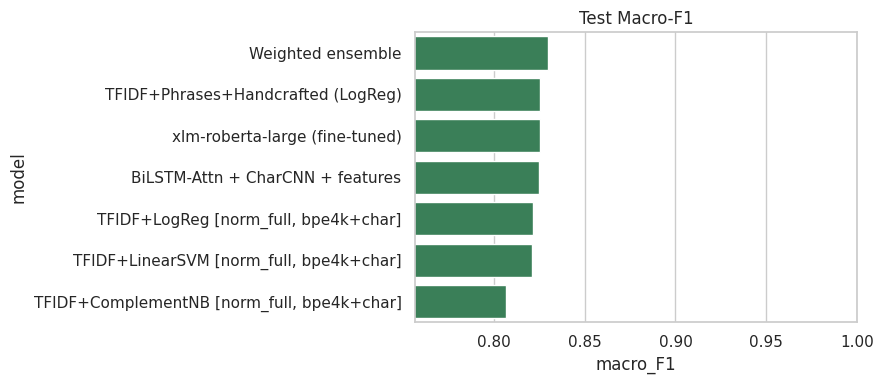

In [90]:
plt.figure(figsize=(9, 4))
sns.barplot(data=res_df, y='model', x='macro_F1', color='seagreen')
plt.xlim(res_df['macro_F1'].min() - 0.05, 1)
plt.title('Test Macro-F1')
plt.tight_layout()
plt.show()

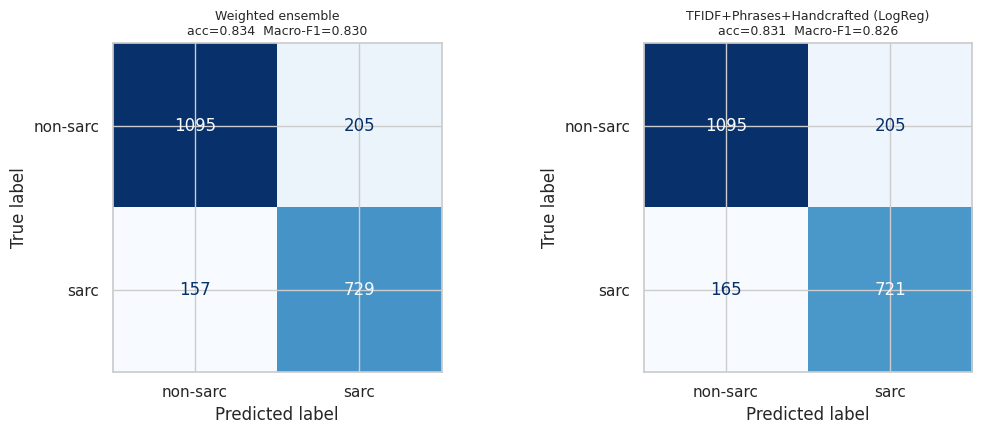

In [91]:
# confusion matrices of the top-2 models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (_, r) in zip(axes, res_df.head(2).iterrows()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, PREDS[r['key']]),
                           display_labels=['non-sarc', 'sarc']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{r['model'][:38]}\nacc={r['acc']:.3f}  Macro-F1={r['macro_F1']:.3f}", fontsize=9)
plt.tight_layout()
plt.show()

In [92]:
def mcnemar(y, a, b):
    b01 = np.sum((a == y) & (b != y))
    b10 = np.sum((a != y) & (b == y))
    stat = (abs(b01 - b10) - 1) ** 2 / max(b01 + b10, 1)
    return b01, b10, 1 - chi2.cdf(stat, 1)

k1, k2 = res_df['key'][0], res_df['key'][1]
b01, b10, p = mcnemar(y_test, PREDS[k1], PREDS[k2])
print(f"McNemar {res_df['model'][0]} vs {res_df['model'][1]}: only-1st={b01}, only-2nd={b10}, p={p:.4f}")

McNemar Weighted ensemble vs TFIDF+Phrases+Handcrafted (LogReg): only-1st=66, only-2nd=58, p=0.5296


## Error Analysis

In [93]:
BEST_KEY, BEST_NAME = res_df['key'][0], res_df['model'][0]

def tag_row(r):
    toks = set(r.txt_norm_full.split())
    tags = []
    if r.n_emoji: tags.append('emoji')
    if r.n_laugh or r.n_mock: tags.append('laugh/mock-emoji')
    if r.has_latin: tags.append('code-mixed')
    if toks & NEG: tags.append('negation')
    if r.n_ques: tags.append('question/rhetorical')
    if r.n_quotes: tags.append('scare-quotes')
    if r.n_elong: tags.append('elongation/spelling')
    if r.n_hashtag: tags.append('hashtag')
    if toks & POS_WORDS: tags.append('positive-word (irony?)')
    if r.n_words <= 4: tags.append('very-short / no context')
    if r.n_words >= 40: tags.append('long')
    return tags

In [94]:
err = test_df.assign(pred=PREDS[BEST_KEY], score=PROBS[BEST_KEY])
err['tags'] = err.apply(tag_row, axis=1)
err['wrong'] = err['pred'] != err['label']
err['type'] = np.select([(err['label'] == 1) & (err['pred'] == 0), (err['label'] == 0) & (err['pred'] == 1)],
                        ['FN (missed sarcasm)', 'FP'], 'correct')

In [95]:
tag_rows = err.explode('tags').dropna(subset=['tags'])
tag_err = tag_rows.groupby('tags').agg(posts=('wrong', 'size'), error_rate=('wrong', 'mean'))
tag_err = tag_err.sort_values('error_rate', ascending=False)
tag_err.loc['(overall)'] = [len(err), err['wrong'].mean()]
print("Error rate by phenomenon —", BEST_NAME)
tag_err.round(3)

Error rate by phenomenon — Weighted ensemble


,posts,error_rate
tags,,
long,193.0,0.228
question/rhetorical,94.0,0.213
laugh/mock-emoji,935.0,0.210
negation,549.0,0.180
emoji,1726.0,0.169
elongation/spelling,33.0,0.121
positive-word (irony?),179.0,0.117
code-mixed,351.0,0.114
scare-quotes,94.0,0.106


In [96]:
conf = np.abs(err['score'] - np.median(err['score']))
mis = err[err['wrong']].assign(confidence=conf[err['wrong']])
sample = pd.concat([mis[mis['type'].str.startswith('FN')].nlargest(8, 'confidence'),
                    mis[mis['type'] == 'FP'].nlargest(7, 'confidence')])
sample['commentary'] = ''

for i, r in enumerate(sample.itertuples(), 1):
    print(f"[{i:02d}] {r.type} | true={LABEL_NAME[r.label]} pred={LABEL_NAME[r.pred]} score={r.score:.3f}")
    print(f"     tags: {', '.join(r.tags) or '-'}")
    print(f"     text: {r.urdu_text}\n")

sample[['urdu_text', 'label', 'pred', 'score', 'type', 'tags', 'commentary']].to_csv(f'{OUT_DIR}/error_analysis.csv', index=False)

[01] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.009
     tags: emoji
     text: صلی اللہ علیہ وآلہ وسلّم🌹🌹🌹🌹🌹

[02] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.015
     tags: emoji, negation
     text: خدا کرے.. تو میری یاد میں خاک چھانے خدا کرے میں تجھے خاک میں بھی نہ ملوں 🌹🌹🌺🥀🥀☘️🌷🌷🌼💐💐🌴🌴💐💐💐💐💐💐💐 اردو_زبان

[03] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.017
     tags: emoji, very-short / no context
     text: 🍃🍃🍃🍃 آپ بھی

[04] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.032
     tags: emoji, laugh/mock-emoji, very-short / no context
     text: تو میرا خیر خاہ😍😂😂😂

[05] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.035
     tags: emoji
     text: السلام عليكم۔۔۔ جیوندے روو۔۔۔ آمین۔۔۔ کی حال نے سونڑیو۔۔۔ 😘😍😘😍

[06] FN (missed sarcasm) | true=Sarcastic pred=Non-sarcastic score=0.037
     tags: emoji
     text: پاکستان پائندہ باد 🇵🇰💚 شب بخیر ❤️

[07] FN (missed sarcasm) | true=Sarcastic pred

## Save

In [ ]:
joblib.dump({'model': fe_lr, 'phrases': PHRASES, 'scaler': hc_scaler, 'kind': BEST_KIND}, f'{OUT_DIR}/fe_lr.joblib')
joblib.dump({'model': tfidf_lr, 'variant': BEST_VAR, 'kind': BEST_KIND}, f'{OUT_DIR}/tfidf_lr.joblib')
torch.save(nn_model.state_dict(), f'{OUT_DIR}/bilstm_charcnn.pt')
with open(f'{OUT_DIR}/nn_vocab.json', 'w', encoding='utf-8') as fh:
    json.dump({'word_vocab': wvocab, 'char_vocab': cvocab}, fh, ensure_ascii=False)

SAVE_TRANSFORMER = False      # ~2.2 GB for the large model
if SAVE_TRANSFORMER and 'tf_model' in globals():
    tf_model.save_pretrained(f'{OUT_DIR}/transformer')
    hf_tok.save_pretrained(f'{OUT_DIR}/transformer')

print(os.listdir(OUT_DIR))


['tfidf_lr.joblib', 'error_analysis.csv', 'fe_lr.joblib', 'bilstm_charcnn.pt', 'nn_vocab.json', 'results.csv']
